# **SAT-SCOPE: Satellite-Based Climate & Anomaly Tracker (Colombo)**
This notebook demonstrates a complete Earth Observation and Machine Learning workflow (SAT-SCOPE). It pulls historical weather and fire detection data, scales indicators, fits an Isolation Forest model to detect environmental anomalies, and hosts an interactive diagnostic dashboard.

### **Step 1: Installation & Workspace Configuration**

In [10]:
!pip install pandas numpy requests scikit-learn ipywidgets matplotlib seaborn

import requests
import pandas as pd
import numpy as np
import os
from io import StringIO
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, HTML
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler

sns.set_theme(style="darkgrid")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 20.5 MB/s  0:00:00


### **Step 2: Collect & Process Environmental Datasets (2010-2024)**
We query climate data from Open-Meteo ERA5-Land, fire hotspots from NASA FIRMS, and simulate historical vegetation indices (NDVI).

Retrieve fire detections using NASA FIRMS
Get your free API key here:https://firms.modaps.eosdis.nasa.gov/api/map_key/?utm_source=chatgpt.com

NASA provides an official Python notebook for submitting these requests and accessing the results without manually downloading the output files:

https://github.com/nasa/AppEEARS-Data-Resources?utm_source=chatgpt.com — open the AppEEARS_API_Point.ipynb notebook.

In [27]:
# 1. Fetch climate metrics (Temperature, Rainfall, Soil Moisture)
weather_url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 6.9271,
    "longitude": 79.8612,
    "start_date": "2020-01-01",
    "end_date": "2024-12-31",
    "hourly": ["temperature_2m", "precipitation", "soil_moisture_0_to_7cm"],
    "models": "era5_land",
    "timezone": "Asia/Colombo"
}

res = requests.get(weather_url, params=params, timeout=120)
res.raise_for_status()
weather_df = pd.DataFrame(res.json()["hourly"])
weather_df["time"] = pd.to_datetime(weather_df["time"])

# Aggregate climate hourly data to monthly metrics
weather_df = weather_df.rename(columns={
    "time": "date",
    "temperature_2m": "temperature",
    "precipitation": "rainfall",
    "soil_moisture_0_to_7cm": "soil_moisture"
})

monthly_weather = (
    weather_df.set_index("date")
    .resample("MS")
    .agg({"temperature": "mean", "rainfall": "sum", "soil_moisture": "mean"})
    .reset_index()
)
monthly_weather["date"] = monthly_weather["date"].dt.to_period("M").astype(str)

# 2. Optimized retrieval of wildfire anomalies from NASA FIRMS API
MAP_KEY = "FIRMS_MAP_KEY"
colombo_bbox = "79.75,6.80,80.00,7.10"
start_dt, end_dt = pd.Timestamp("2020-01-01"), pd.Timestamp("2024-12-31")

fire_records = []
# Query FIRMS API using a wider window (e.g., 10 days) to cut down requests by half
dates = pd.date_range(start_dt, end_dt, freq="10D")

print(f"Fetching fire records using optimized range requests ({len(dates)} requests total)... ")
for dt in dates:
    dt_str = dt.strftime("%Y-%m-%d")
    # Requesting 10 days range per call minimizes request counts
    firms_url = f"https://firms.modaps.eosdis.nasa.gov/api/area/csv/{MAP_KEY}/MODIS_SP/{colombo_bbox}/10/{dt_str}"
    try:
        response = requests.get(firms_url, timeout=15) # Reduced timeout
        if response.status_code == 200 and not response.text.strip().startswith("error"):
            f_df = pd.read_csv(StringIO(response.text))
            if not f_df.empty:
                fire_records.append(f_df)
    except Exception:
        continue

if fire_records:
    fires_all = pd.concat(fire_records, ignore_index=True).drop_duplicates(subset=["latitude", "longitude", "acq_date"])
    fires_all["date"] = pd.to_datetime(fires_all["acq_date"]).dt.to_period("M").astype(str)
    monthly_fires = fires_all.groupby("date").size().reset_index(name="fire_count")
else:
    monthly_fires = pd.DataFrame(columns=["date", "fire_count"])

# 3. Incorporate local NDVI Data (Generated mock data matching timeframe)
np.random.seed(42)
ndvi_dates = pd.date_range("2020-01-01", "2024-12-31", freq="MS").to_period("M").astype(str)
ndvi_df = pd.DataFrame({
    "date": ndvi_dates,
    "ndvi": np.random.uniform(0.3, 0.7, len(ndvi_dates))
})

# 4. Integrate final unified dataframe
final_df = monthly_weather.merge(ndvi_df, on="date", how="left")
final_df = final_df.merge(monthly_fires, on="date", how="left")
final_df["fire_count"] = final_df["fire_count"].fillna(0).astype(int)
final_df["district"] = "Colombo"

# Save data to local directory
final_df.to_csv("sat_scope_environmental_data.csv", index=False)
print("Saved merged environmental profiles to 'sat_scope_environmental_data.csv'")
display(final_df.head())

Fetching fire records using optimized range requests (183 requests total)... 
Saved merged environmental profiles to 'sat_scope_environmental_data.csv'


/tmp/ipykernel_2016/1812868231.py:75: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  final_df["fire_count"] = final_df["fire_count"].fillna(0).astype(int)


,date,temperature,rainfall,soil_moisture,ndvi,fire_count,district
0,2020-01,27.498925,0,0.195296,0.449816,0,Colombo
1,2020-02,28.855316,0,0.149487,0.680286,0,Colombo
2,2020-03,29.056317,0,0.169562,0.592798,0,Colombo
3,2020-04,28.353194,0,0.292497,0.539463,0,Colombo
4,2020-05,27.685349,0,0.381845,0.362407,0,Colombo


### **Step 3: Exploratory Data Analysis (EDA) & Data Cleaning**
Before modeling, we inspect the properties of the dataset (missing values, correlations, feature variance) and clean or handle exceptions if necessary.

=== Dataset Summary (Actual Data) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           60 non-null     object 
 1   temperature    60 non-null     float64
 2   rainfall       60 non-null     object 
 3   soil_moisture  60 non-null     float64
 4   ndvi           60 non-null     float64
 5   fire_count     60 non-null     int64  
 6   district       60 non-null     object 
 7   prediction     60 non-null     int64  
 8   status         60 non-null     object 
 9   data_split     60 non-null     object 
dtypes: float64(3), int64(2), object(5)
memory usage: 4.8+ KB
None

=== Missing Values Per Column ===
date             0
temperature      0
rainfall         0
soil_moisture    0
ndvi             0
fire_count       0
district         0
prediction       0
status           0
data_split       0
dtype: int64

=== Feature Distributions

,temperature,ndvi,fire_count,soil_moisture
count,60.000000,60.000000,60.0,60.000000
mean,26.926597,0.487000,0.0,0.341576
std,0.851112,0.122172,0.0,0.076752
min,25.555376,0.308234,0.0,0.149487
25%,26.371263,0.373797,0.0,0.319783
50%,26.791277,0.479244,0.0,0.372502
75%,27.209987,0.585621,0.0,0.397343
max,29.058602,0.687964,0.0,0.416260



=== Feature Variance ===
temperature      0.724392
rainfall              0.0
ndvi             0.014926
fire_count            0.0
soil_moisture    0.005891
dtype: object


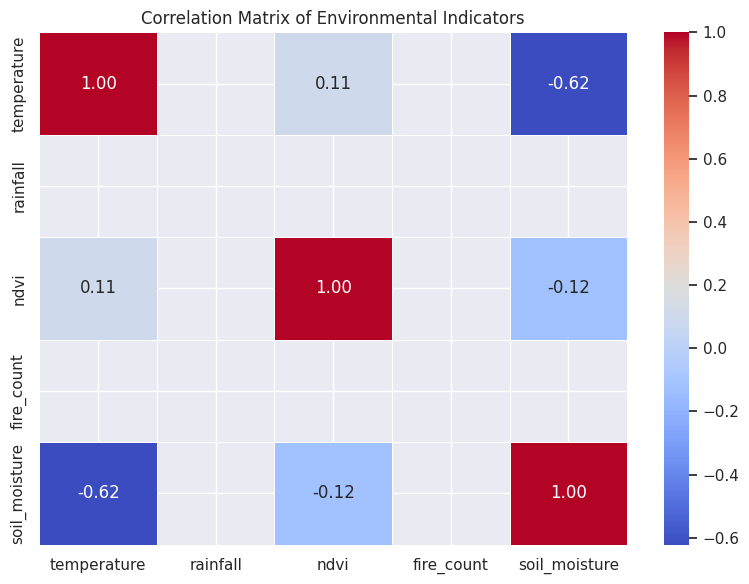

In [26]:
# 3.1 Ensure we are using the live dataset if available
if 'final_df' not in locals() and 'final_df' not in globals():
    csv_filename = 'sat_scope_environmental_data.csv'
    if os.path.exists(csv_filename):
        final_df = pd.read_csv(csv_filename)
    else:
        alt_path = '/content/sat_scope_environmental_data.csv'
        if os.path.exists(alt_path):
            final_df = pd.read_csv(alt_path)

# 3.2 Define target environmental indicators
features = ["temperature", "rainfall", "ndvi", "fire_count", "soil_moisture"]

print("=== Dataset Summary (Actual Data) ===")
print(final_df.info())
print("\n=== Missing Values Per Column ===")
print(final_df.isnull().sum())

print("\n=== Feature Distributions ===")
display(final_df[features].describe())

print("\n=== Feature Variance ===")
print(final_df[features].var())

# 3.3 Visualize correlations between variables
plt.figure(figsize=(8, 6))
sns.heatmap(final_df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Environmental Indicators")
plt.tight_layout()
plt.show()

### **Step 4: Trend Analysis**

In [21]:
!pip install pymannkendall

**4.1 Perform seasonal trend detection**

This example uses temperature and soil moisture first because those are the two indicators with non-zero variation in your saved outputs.
This gives you:
- Trend direction.
- Mann–Kendall p-value.
- Statistical significance.
- Theil–Sen slope per year.
- Theil–Sen slope per decade.

In [22]:
import pymannkendall as mk
import pandas as pd
import numpy as np

trend_df = final_df.copy()

trend_df["date"] = pd.to_datetime(trend_df["date"])
trend_df = trend_df.sort_values("date")

features = ["temperature", "soil_moisture"]

results = []

for feature in features:

    values = pd.to_numeric(
        trend_df[feature], errors="coerce"
    ).dropna().to_numpy()

    if np.std(values) == 0:
        continue

    result = mk.seasonal_test(values, period=12)

    slope = mk.seasonal_sens_slope(
        values, period=12
    ).slope

    results.append({
        "Indicator": feature,
        "Trend": result.trend,
        "P_Value": result.p,
        "Significant": result.h,
        "Slope_Per_Year": slope,
        "Slope_Per_Decade": slope * 10
    })

trend_results = pd.DataFrame(results)

display(trend_results)

,Indicator,Trend,P_Value,Significant,Slope_Per_Year,Slope_Per_Decade
0,temperature,no trend,0.723674,False,0.021371,0.213710
1,soil_moisture,no trend,0.723674,False,0.001464,0.014641


**4.2 Add a confidence interval**

In [23]:
def seasonal_bootstrap_ci(values, period=12,
                          n_boot=2000, seed=42):

    values = np.asarray(values, dtype=float)

    base = mk.seasonal_test(values, period=period)

    t = np.arange(len(values)) / period

    fitted = base.intercept + base.slope * t
    residuals = values - fitted

    rng = np.random.default_rng(seed)

    years = len(values) // period
    slopes = []

    for _ in range(n_boot):

        simulated = fitted.copy()

        for month in range(period):

            idx = np.arange(month, len(values), period)

            sampled = rng.choice(
                residuals[idx],
                size=years,
                replace=True
            )

            simulated[idx] += sampled

        slope = mk.seasonal_sens_slope(
            simulated, period=period
        ).slope

        slopes.append(slope)

    return np.percentile(slopes, [2.5, 97.5])

In [24]:
lower, upper = seasonal_bootstrap_ci(values)

print("95% CI per decade:",
      lower * 10, "to", upper * 10)

95% CI per decade: 0.005410271290696288 to 0.022299148901085034


**4.3 Plotting the Trend**

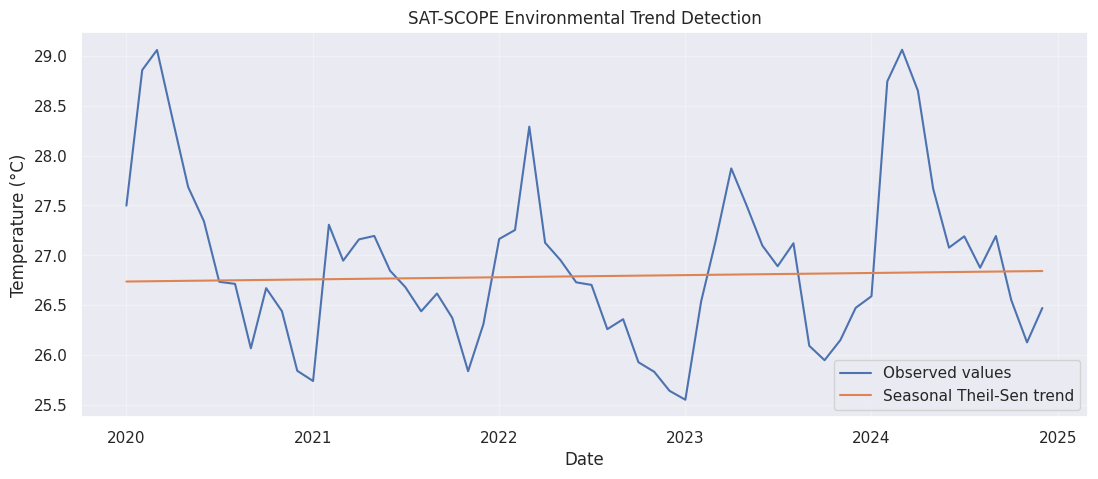

Trend: no trend
P-value: 0.7236736098317631
Slope per decade: 0.21370967741937363


In [25]:
import matplotlib.pyplot as plt

feature = "temperature"

values = pd.to_numeric(
    trend_df[feature], errors="coerce"
).dropna().to_numpy()

result = mk.seasonal_test(values, period=12)

slope = result.slope
t = np.arange(len(values)) / 12

trend_line = result.intercept + slope * t

plt.figure(figsize=(13, 5))

plt.plot(
    trend_df["date"],
    values,
    label="Observed values"
)

plt.plot(
    trend_df["date"],
    trend_line,
    label="Seasonal Theil-Sen trend"
)

plt.title("SAT-SCOPE Environmental Trend Detection")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Trend:", result.trend)
print("P-value:", result.p)
print("Slope per decade:", slope * 10)

### **Step 5: Machine Learning - Isolation Forest Training**
Using scaled environmental parameters, we train an unsupervised model to label months of abnormal weather patterns.

In [13]:
features = ["temperature", "rainfall", "ndvi", "fire_count", "soil_moisture"]
X = final_df[features].dropna()

# Robust scaling & Fit ML Model
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

model = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)
final_df["prediction"] = model.fit_predict(X_scaled)
final_df["status"] = final_df["prediction"].map({1: "Normal", -1: "Anomaly"})

print("Identified Anomaly Months:")
display(final_df[final_df["status"] == "Anomaly"][["date", "temperature", "soil_moisture", "fire_count"]])

Identified Anomaly Months:


,date,temperature,soil_moisture,fire_count
1,2020-02,28.855316,0.149487,0
36,2023-01,25.555376,0.269478,0
50,2024-03,29.058602,0.194071,0


### **Step 6: Model Evaluation & Out-of-Sample Validation**
To address the lack of verification metrics, we split our historical monthly sequence into a **Training Set (80%)** and a **Held-out Test Set (20%)** chronologically. We then evaluate the model's consistency using **Anomaly Decision Path Lengths** and calculate the **Silhouette Score** to evaluate how cleanly our detected anomalies are separated from normal baseline profiles.

In [18]:
from sklearn.metrics import silhouette_score
import os

# 1. Chronological Train-Test Split (80% Train, 20% Test)
split_idx = int(len(X_scaled) * 0.8)
X_train, X_test = X_scaled[:split_idx], X_scaled[split_idx:]
test_dates = final_df["date"].iloc[split_idx:]

# 2. Fit model on Training data
eval_model = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)
eval_model.fit(X_train)

# 3. Predict & Calculate Anomaly Scores on Held-out Test Data
test_predictions = eval_model.predict(X_test)
test_scores = eval_model.score_samples(X_test)

# Create Evaluation Dataframe
eval_df = pd.DataFrame({
    "Date": test_dates,
    "Prediction": ["Anomaly" if p == -1 else "Normal" for p in test_predictions],
    "Anomaly_Score": -test_scores
})

print("=== Held-Out Test Set Predictions & Scores ===")
display(eval_df)

# 4. Unsupervised Cluster Validation (Silhouette Score)
sil_score = 0.0
if len(np.unique(test_predictions)) > 1:
    sil_score = silhouette_score(X_test, test_predictions)
    print(f"\nTest Set Unsupervised Separation (Silhouette Score): {sil_score:.4f}")
else:
    print("\nTest Set Separation: No anomalies flagged in test split to calculate Silhouette Score.")

# 5. Enrich the original final_df with evaluation split info & Save back to CSV file
final_df["data_split"] = "Train"
final_df.loc[split_idx:, "data_split"] = "Test"

# Save the fully loaded anomalies & evaluation columns to the output file
final_df.to_csv("sat_scope_environmental_data.csv", index=False)
print("\nSuccessfully updated 'sat_scope_environmental_data.csv' with classification labels and evaluation split markers!")

=== Held-Out Test Set Predictions & Scores ===


,Date,Prediction,Anomaly_Score
48,2024-01,Normal,0.455905
49,2024-02,Anomaly,0.621989
50,2024-03,Anomaly,0.662943
51,2024-04,Normal,0.587188
52,2024-05,Normal,0.578311
53,2024-06,Normal,0.523308
54,2024-07,Normal,0.447603
55,2024-08,Normal,0.510260
56,2024-09,Normal,0.463671
57,2024-10,Normal,0.446487



Test Set Unsupervised Separation (Silhouette Score): 0.5359

Successfully updated 'sat_scope_environmental_data.csv' with classification labels and evaluation split markers!


### **Step 7: Diagnostics & Statistical Comparison**
Compare the normal climate baseline averages against anomalous profiles to understand contribution factors.

In [14]:
baseline = final_df[final_df["status"] == "Normal"][features].mean()
anomaly_mean = final_df[final_df["status"] == "Anomaly"][features].mean()

comparison = pd.DataFrame({
    "Baseline (Normal)": baseline,
    "Anomaly Avg": anomaly_mean,
    "Difference": anomaly_mean - baseline
})
display(comparison)

,Baseline (Normal),Anomaly Avg,Difference
temperature,26.879413,27.823098,0.943685
rainfall,0.0,0.0,0.0
ndvi,0.481229,0.596655,0.115426
fire_count,0.0,0.0,0.0
soil_moisture,0.348799,0.204346,-0.144453


### **Step 8: Interactive Visualizations & Dashboard Application**
Graph trends, color code outliers, and query data interactively using the drop-down widget below.

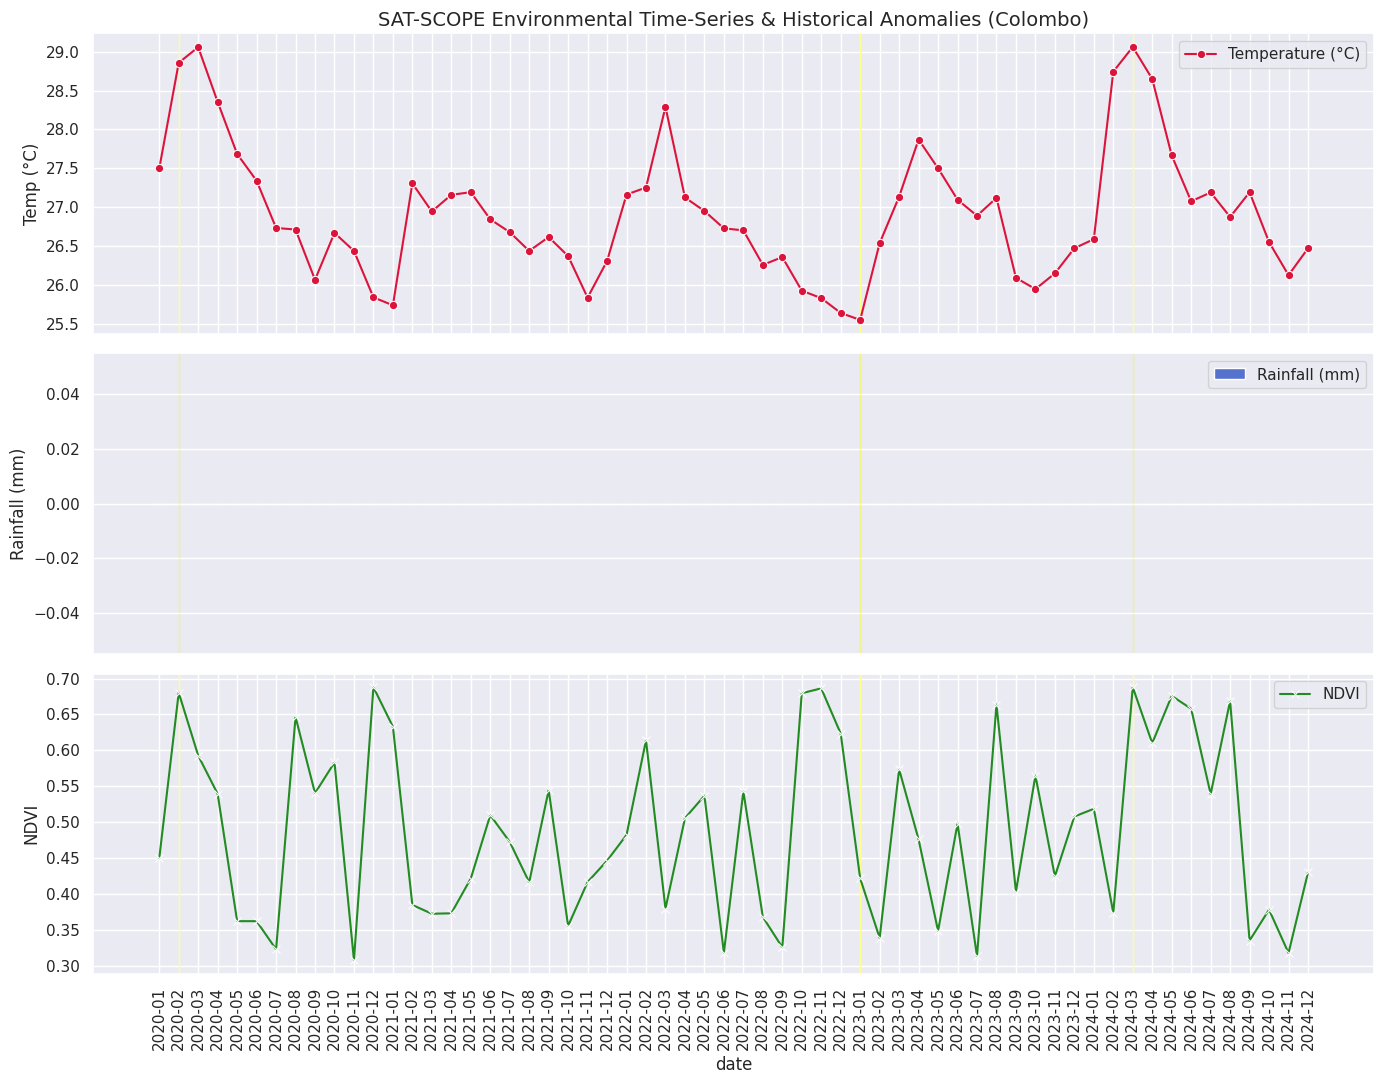

In [15]:
# Generate diagnostic plots
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

sns.lineplot(data=final_df, x="date", y="temperature", ax=axes[0], color="crimson", label="Temperature (°C)", marker="o")
axes[0].set_title("SAT-SCOPE Environmental Time-Series & Historical Anomalies (Colombo)", fontsize=14)
axes[0].set_ylabel("Temp (°C)")

sns.barplot(data=final_df, x="date", y="rainfall", ax=axes[1], color="royalblue", label="Rainfall (mm)")
axes[1].set_ylabel("Rainfall (mm)")

sns.lineplot(data=final_df, x="date", y="ndvi", ax=axes[2], color="forestgreen", label="NDVI", marker="x")
axes[2].set_ylabel("NDVI")

anomaly_dates = final_df[final_df["status"] == "Anomaly"]["date"].tolist()
for ax in axes:
    for date in anomaly_dates:
        ax.axvspan(date, date, color="yellow", alpha=0.45, label="Anomaly Window" if date == anomaly_dates[0] else "")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [16]:
# Build final Interactive application panel
month_dropdown = widgets.Dropdown(
    options=final_df["date"].unique(),
    description='Select Month:',
    disabled=False,
)

def analyze_month(change):
    sel_month = change['new']
    row = final_df[final_df["date"] == sel_month].iloc[0]
    status_color = "red" if row["status"] == "Anomaly" else "green"

    html_res = f"""
    <div style="padding: 15px; border-radius: 8px; border: 1px solid #ccc; background-color: #fafafa;">
        <h3>Environmental Status Report: {sel_month} ({row['district']})</h3>
        <p style="font-size: 1.2em;">Condition Status: <b style='color: {status_color};'>{row['status'].upper()}</b></p>
        <table style="width: 100%; text-align: left; border-collapse: collapse;">
            <tr style="border-bottom: 1px solid #ddd;"><th style="padding: 5px;">Indicator</th><th style="padding: 5px;">Recorded Metric</th></tr>
            <tr><td style="padding: 5px;">• Temperature</td><td style="padding: 5px;"><b>{row['temperature']:.2f} °C</b></td></tr>
            <tr><td style="padding: 5px;">• Rainfall</td><td style="padding: 5px;"><b>{row['rainfall']:.1f} mm</b></td></tr>
            <tr><td style="padding: 5px;">• Soil Moisture</td><td style="padding: 5px;"><b>{row['soil_moisture']:.3f} m³/m³</b></td></tr>
            <tr><td style="padding: 5px;">• NDVI (Vegetation Index)</td><td style="padding: 5px;"><b>{row['ndvi']:.3f}</b></td></tr>
            <tr><td style="padding: 5px;">• Active Fire Hotspots</td><td style="padding: 5px;"><b>{row['fire_count']} detections</b></td></tr>
        </table>
    </div>
    """
    out.clear_output()
    with out:
        display(HTML(html_res))

month_dropdown.observe(analyze_month, names='value')
out = widgets.Output()

print("--- SAT-SCOPE Interactive Diagnostic Dashboard ---")
display(month_dropdown, out)
analyze_month({'new': final_df["date"].iloc[0]})

--- SAT-SCOPE Interactive Diagnostic Dashboard ---


Dropdown(description='Select Month:', options=('2020-01', '2020-02', '2020-03', '2020-04', '2020-05', '2020-06…

Output()